# Hugging Face. Табличные трансформеры на Cars

Материал обращён к студенту. Пояснения сопровождают код, а блоки **«Задание»** содержат самостоятельные действия.

Сравним TabPFN 2.5, TabICLv2 и линейную регрессию. Проверим число известных примеров, числовые и категориальные признаки, состав контекста и логарифм цены. В конце оценим модели на test.

### Установка

В отдельной ячейке выполните команду, затем перезапустите ядро.

    %pip install "torch>=2.8" "tabpfn==9.2.0" "tabicl==2.2.0" pandas scikit-learn matplotlib

Веса занимают примерно 41 и 114 МБ и скачиваются один раз. Используем CPU и n_estimators=1. Это фиксированный быстрый режим для всех основных сравнений.

## 1. Данные, признаки и проверка качества

### Загружаем таблицу

В cars находятся все доступные столбцы. Наличие столбца в таблице ещё не означает, что мы передали его модели. Используемые признаки зададим отдельно.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

torch.set_num_threads(4)

In [2]:
path = Path("cars_processed.csv")
url = "https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/refs/heads/main/Workshops/cars_processed.csv"
cars = pd.read_csv(path if path.exists() else url)
cars.head()

,Make,Model,Year,Style,Distance,Engine,Fuel_type,AutoTransmission,Price,Age,km_year
0,Toyota,Prius,2011,Hatchback,195000.0,1800.0,Hybrid,True,7750.0,11,17727.272727
1,Renault,Grand Scenic,2014,Universal,135000.0,1500.0,Diesel,False,8550.0,8,16875.000000
2,Renault,Laguna,2012,Universal,110000.0,1500.0,Diesel,False,6550.0,10,11000.000000
3,Opel,Astra,2006,Universal,200000.0,1600.0,Metan/Propan,False,4100.0,16,12500.000000
4,Mercedes,Vito,2000,Microvan,300000.0,2200.0,Diesel,False,3490.0,22,13636.363636


### Пока берём только четыре числовых столбца

| Столбец | Содержание |
|---|---|
| Year | Год выпуска |
| Distance | Пробег |
| Engine | Объём двигателя |
| km_year | Среднегодовой пробег |

Это сведения об автомобиле. Марку, модель, топливо и кузов добавим отдельным опытом. Во всех запусках до раздела 4 в fit() и predict() передаём только numeric_features.

In [3]:
numeric_features = ["Year", "Distance", "Engine", "km_year"]
cars[numeric_features].head()

,Year,Distance,Engine,km_year
0,2011,195000.0,1800.0,17727.272727
1,2014,135000.0,1500.0,16875.000000
2,2012,110000.0,1500.0,11000.000000
3,2006,200000.0,1600.0,12500.000000
4,2000,300000.0,2200.0,13636.363636


### Для чего нужны train, context, validation и test

| Переменная | Для чего нужна |
|---|---|
| train_pool | Часть исходной таблицы, из которой выбираем известные примеры |
| context | 1 000 выбранных автомобилей с известными ценами |
| valid | 300 других автомобилей для сравнения вариантов |
| test | 500 других автомобилей для итоговой оценки |

И TAB, и LR получают известные цены только из своей обучающей части. У TAB эти строки служат контекстом. У LR по ним подбираются коэффициенты. Правильные цены valid и test нужны для расчёта ошибок после прогноза.

In [4]:
train_pool, holdout = train_test_split(cars, test_size=0.4, random_state=42)
valid_pool, test_pool = train_test_split(holdout, test_size=0.5, random_state=43)

#### Выбираем небольшой объём для быстрых опытов

sample(n=1000) случайно выбирает 1 000 строк. random_state фиксирует выбор. Для опыта с недорогими машинами позже выберем отдельные 200 строк из train_pool.

In [5]:
context = train_pool.sample(n=1000, random_state=42)
valid = valid_pool.sample(n=300, random_state=42)
test = test_pool.sample(n=500, random_state=42)
pd.Series({"Контекст": len(context), "Validation": len(valid), "Test": len(test)})

Контекст      1000
Validation     300
Test           500
dtype: int64

### Что здесь называют zero-shot

| Режим по числу примеров | Известные примеры текущей задачи |
|---|---:|
| Zero-shot | 0 |
| One-shot | 1 |
| Few-shot | Несколько |

В описаниях табличных foundation models выражение **zero-shot transfer** означает применение готовой модели к новому датасету без дообучения её весов. При этом модель получает строки с правильными ответами как контекст.

**В этой работе выполняем in-context learning с 50, 200 и 1 000 известными автомобилями.** Это не запуск без примеров текущей задачи. fit() подготавливает выбранный контекст, а predict() использует его для новых строк. Предобученные веса при этом остаются прежними.

fit() подготавливает этот контекст для TAB. Название метода совпадает с API sklearn, где fit() у линейной регрессии обучает коэффициенты. [Описание работы TabICL](https://tabicl.readthedocs.io/en/latest/).

### Две метрики в евро

MAE — средний модуль промаха. RMSE сильнее реагирует на большие промахи. Для моделей с логарифмом сначала возвращаем прогноз в евро и только потом считаем обе метрики.

Функция evaluate() возвращает одну строку таблицы. Её используем после каждого запуска.

In [6]:
def evaluate(name, actual, predicted):
    return pd.DataFrame({"Вариант": [name],
                         "MAE, евро": [mean_absolute_error(actual, predicted)],
                         "RMSE, евро": [root_mean_squared_error(actual, predicted)]})

## 2. Первые прогнозы

### Загружаем конкретные веса

В model_path передадим путь к выбранным весам. Веса взяты с [Hugging Face для TabPFN 2.5](https://huggingface.co/Prior-Labs/tabpfn_2_5) и [TabICLv2](https://huggingface.co/jingang/TabICL).

In [7]:
from huggingface_hub import hf_hub_download
from tabpfn import TabPFNRegressor
from tabicl import TabICLRegressor

pfn_path = hf_hub_download("Prior-Labs/tabpfn_2_5", "tabpfn-v2.5-regressor-v2.5_default.ckpt",
                           revision="6c45f3a6d0d07c6c5f62572e04a0c2929de91b8b")
icl_path = hf_hub_download("jingang/TabICL", "tabicl-regressor-v2-20260212.ckpt",
                           revision="4dcd344ece2c00be9e831fdd35bed57b5ad83e19")

### Берём первые 50 известных автомобилей

iloc[:50] выбирает первые 50 строк **по позиции**. Набор context уже был случайно перемешан при sample().

In [8]:
known_50 = context.iloc[:50]
known_50[numeric_features + ["Price"]].head()

,Year,Distance,Engine,km_year,Price
28259,2014,90000.0,1500.0,11250.000000,11000.0
12254,2013,90000.0,1500.0,10000.000000,6850.0
24067,1998,220000.0,1500.0,9166.666667,700.0
3435,2004,25800.0,1400.0,1433.333333,4200.0
23929,2006,199000.0,1900.0,12437.500000,3300.0


### TabPFN 2.5: что делает fit()

TabPFNRegressor — готовый предобученный трансформер для регрессии по таблицам.

В этом опыте `pfn.fit(X, y)` **не обновляет веса трансформера**. Метод подготавливает преобразования признаков и цены по известным строкам и сохраняет подготовленный контекст для последующих прогнозов. При необходимости библиотека загружает готовые веса.

`predict()` использует этот контекст и признаки нового автомобиля. Его правильная цена модели неизвестна. При следующем `fit()` контекст заменяется.

У обычной линейной регрессии смысл `fit()` другой: она оценивает коэффициенты по переданным данным.

In [9]:
pfn = TabPFNRegressor(model_path=pfn_path, n_estimators=1, device="cpu", random_state=42)
# Готовим контекст из 50 машин; веса трансформера остаются фиксированными.
pfn.fit(known_50[numeric_features], known_50["Price"])
pfn_prediction = pfn.predict(valid[numeric_features])
evaluate("TabPFN / 50 примеров", valid["Price"], pfn_prediction).round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabPFN / 50 примеров,2462.0,3735.0


### TabICLv2 на тех же строках

`TabICLRegressor` — интерфейс другого предобученного табличного трансформера для регрессии. Он прогнозирует числовую цель, здесь — цену автомобиля.

Его `fit()` подготавливает числовое представление входов, масштабирование цены и контекст; при необходимости загружает готовые веса. **В нашем режиме веса также не дообучаются.** `predict()` выполняет in-context prediction по известным строкам.

[Документация TabICL: fit и predict](https://tabicl.readthedocs.io/en/latest/).

In [10]:
# TabICLRegressor — готовый табличный трансформер для числового прогноза.
icl = TabICLRegressor(model_path=icl_path, n_estimators=1, device="cpu", n_jobs=4, random_state=42)
# Подготовка контекста, без изменения весов трансформера.
icl.fit(known_50[numeric_features], known_50["Price"])
icl_prediction = icl.predict(valid[numeric_features])
evaluate("TabICL / 50 примеров", valid["Price"], icl_prediction).round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabICL / 50 примеров,2786.0,4238.0


## 3. Эксперимент 1. Число известных примеров

### TabPFN на 50, 200 и 1 000 строках

Один цикл повторяет три одинаковых действия. В каждой итерации выбираем известные строки, получаем прогноз и сохраняем одну строку с метриками. Вложенных циклов здесь нет.

In [11]:
pfn_rows = []
for size in [50, 200, 1000]:
    known = context.iloc[:size]
    pfn.fit(known[numeric_features], known["Price"])
    prediction = pfn.predict(valid[numeric_features])
    result = evaluate("TabPFN 2.5", valid["Price"], prediction)
    result["Примеров"] = size
    pfn_rows.append(result)
pfn_sizes = pd.concat(pfn_rows, ignore_index=True)
pfn_sizes.round(0)

,Вариант,"MAE, евро","RMSE, евро",Примеров
0,TabPFN 2.5,2462.0,3735.0,50
1,TabPFN 2.5,2488.0,4425.0,200
2,TabPFN 2.5,2228.0,4050.0,1000


### Повторяем для TabICLv2

In [12]:
icl_rows = []
for size in [50, 200, 1000]:
    known = context.iloc[:size]
    icl.fit(known[numeric_features], known["Price"])
    prediction = icl.predict(valid[numeric_features])
    result = evaluate("TabICLv2", valid["Price"], prediction)
    result["Примеров"] = size
    icl_rows.append(result)
icl_sizes = pd.concat(icl_rows, ignore_index=True)
icl_sizes.round(0)

,Вариант,"MAE, евро","RMSE, евро",Примеров
0,TabICLv2,2786.0,4238.0,50
1,TabICLv2,2574.0,4536.0,200
2,TabICLv2,2192.0,3869.0,1000


### Собираем таблицу для графика

concat() соединяет результаты по строкам. pivot() располагает размер контекста по строкам, а названия моделей — по столбцам.

In [13]:
numeric_results = pd.concat([pfn_sizes, icl_sizes], ignore_index=True)
curve = numeric_results.pivot(index="Примеров", columns="Вариант", values="MAE, евро")
curve.round(0)

Вариант,TabICLv2,TabPFN 2.5
Примеров,,
50,2786.0,2462.0
200,2574.0,2488.0
1000,2192.0,2228.0


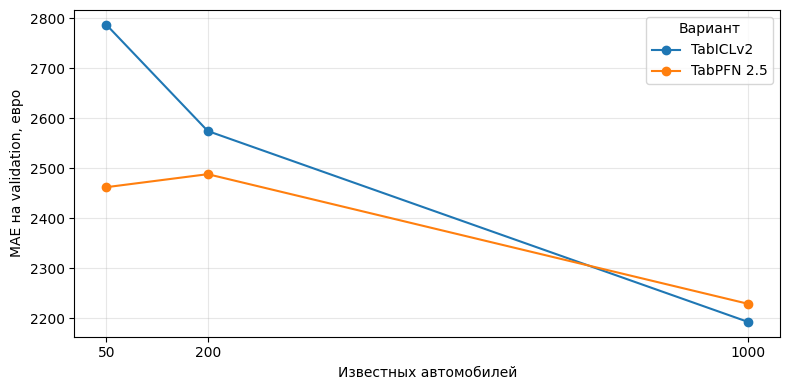

In [14]:
curve.plot(marker="o", figsize=(8, 4))
plt.xticks([50, 200, 1000])
plt.xlabel("Известных автомобилей")
plt.ylabel("MAE на validation, евро")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Задание студенту

Измените random_state только в строке выбора context в разделе 1. Повторите опыт. Объясните, повторяется ли изменение MAE между 50 и 200 примерами при другом составе известных автомобилей. Validation оставьте прежним.

## 4. Эксперимент 2. Добавляем категориальные признаки

### Какие столбцы использовали и какие добавляем

| До этого опыта | Добавляем сейчас |
|---|---|
| Year, Distance, Engine, km_year | Make, Model, Fuel_type, Style |
| Четыре числовых признака | Четыре категориальных признака |

Теперь обе модели получают восемь столбцов. Размер контекста фиксируем на 1 000 строках. Изменение MAE и RMSE относится к добавлению категориальных признаков.

In [15]:
category_features = ["Make", "Model", "Fuel_type", "Style"]
expanded_features = numeric_features + category_features
context[expanded_features].head()

,Year,Distance,Engine,km_year,Make,Model,Fuel_type,Style
28259,2014,90000.0,1500.0,11250.000000,Nissan,Qashqai,Diesel,Crossover
12254,2013,90000.0,1500.0,10000.000000,Renault,Scenic,Diesel,Minivan
24067,1998,220000.0,1500.0,9166.666667,KIA,Shuma,Metan/Propan,Sedan
3435,2004,25800.0,1400.0,1433.333333,Volkswagen,Golf,Petrol,Hatchback
23929,2006,199000.0,1900.0,12437.500000,Rare,159,Diesel,Sedan


### Сообщаем тип добавленных столбцов

`astype("category")` помечает столбец как категориальный в pandas. Мы передаём названия марок и моделей; сами числовые коды здесь не создаём. Набор входов задаётся списком `expanded_features`.

#### Кто кодирует категории

В используемых версиях **обе библиотеки сами выполняют первичное ordinal-кодирование**: каждой категории сопоставляют целочисленный код. Соответствие настраивается при `fit()` по контексту и применяется при `predict()`. Для неизвестных категорий предусмотрена обработка внутри библиотеки.

Код — идентификатор категории: его величина не означает, что одна марка лучше или дороже другой. TabPFN дополнительно преобразует признаки внутри своего конвейера. Поэтому «восемь столбцов» означает восемь исходных входов, а не отсутствие кодирования.

У линейной регрессии ниже будет другой, явно заданный способ: `OneHotEncoder` создаёт отдельные индикаторы категорий.

In [16]:
context[category_features] = context[category_features].astype("category")
valid[category_features] = valid[category_features].astype("category")
test[category_features] = test[category_features].astype("category")
context[expanded_features].dtypes

Year            int64
Distance      float64
Engine        float64
km_year       float64
Make         category
Model        category
Fuel_type    category
Style        category
dtype: object

### TabPFN получает восемь исходных столбцов

Четыре числовых столбца и четыре столбца с категориями передаём вместе. Первичное кодирование категорий выполняет библиотека.

`clone()` создаёт отдельный экземпляр с теми же настройками. `pfn_price.fit()` готовит для него контекст из 1 000 строк с восемью входами и обычной ценой.

In [17]:
pfn_price = clone(pfn)
pfn_price.fit(context[expanded_features], context["Price"])
pfn_price_valid = pfn_price.predict(valid[expanded_features])
pfn_price_score = evaluate("TabPFN / Price", valid["Price"], pfn_price_valid)
pfn_price_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabPFN / Price,2075.0,3892.0


### TabICLv2 получает те же восемь столбцов

In [18]:
icl_price = clone(icl)
icl_price.fit(context[expanded_features], context["Price"])
icl_price_valid = icl_price.predict(valid[expanded_features])
icl_price_score = evaluate("TabICL / Price", valid["Price"], icl_price_valid)
icl_price_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabICL / Price,1997.0,3821.0


### Сравниваем с четырьмя числовыми признаками

Выражение в квадратных скобках оставляет строки, где число примеров равно 1 000. Затем соединяем результаты двух наборов признаков.

In [19]:
numeric_1000 = numeric_results.loc[numeric_results["Примеров"] == 1000].copy()
numeric_1000["Признаки"] = "4 числовых"
category_results = pd.concat([pfn_price_score, icl_price_score], ignore_index=True)
category_results["Признаки"] = "4 числовых + 4 категориальных"
category_results["Примеров"] = 1000
feature_comparison = pd.concat([numeric_1000, category_results], ignore_index=True)
feature_comparison[["Вариант", "Признаки", "Примеров", "MAE, евро", "RMSE, евро"]].round(0)

,Вариант,Признаки,Примеров,"MAE, евро","RMSE, евро"
0,TabPFN 2.5,4 числовых,1000,2228.0,4050.0
1,TabICLv2,4 числовых,1000,2192.0,3869.0
2,TabPFN / Price,4 числовых + 4 категориальных,1000,2075.0,3892.0
3,TabICL / Price,4 числовых + 4 категориальных,1000,1997.0,3821.0


#### Задание студенту

Оставьте в category_features только Make и Model. Снова выполните раздел 4. Затем проверьте только Fuel_type и Style. По разностям метрик объясните, какая информация дала большую часть улучшения.

## 5. Эксперимент 3. Состав контекста

### 5.1. Случайные или только недорогие машины

#### Первый контекст — случайные 200 строк

`iloc[:200]` берёт первые 200 строк уже случайно выбранного `context`. Сохраняем их в отдельную переменную `random_context`.

In [20]:
random_context = context.iloc[:200]
random_context[numeric_features + ["Price"]].head()

,Year,Distance,Engine,km_year,Price
28259,2014,90000.0,1500.0,11250.000000,11000.0
12254,2013,90000.0,1500.0,10000.000000,6850.0
24067,1998,220000.0,1500.0,9166.666667,700.0
3435,2004,25800.0,1400.0,1433.333333,4200.0
23929,2006,199000.0,1900.0,12437.500000,3300.0


### Второй контекст — 200 недорогих машин

Сначала найдём медиану цены в train_pool. Затем создадим условие отбора. Булев ряд cheap_mask содержит True для подходящих строк.

In [21]:
price_limit = train_pool["Price"].median()
cheap_mask = train_pool["Price"] <= price_limit
print("Граница цены:", price_limit)
cheap_mask.head()

Граница цены: 6799.0


22222     True
3091     False
24316     True
22327     True
13572    False
Name: Price, dtype: bool

### Отбираем подходящие строки через loc

loc[cheap_mask] оставляет строки с True. После этого sample() случайно выбирает 200 из отобранных автомобилей.

In [22]:
cheap_pool = train_pool.loc[cheap_mask]
cheap_context = cheap_pool.sample(n=200, random_state=42)
cheap_context[numeric_features + ["Price"]].head()

,Year,Distance,Engine,km_year,Price
24530,2005,300000.0,3000.0,17647.058824,5000.0
27877,1999,145000.0,2200.0,6304.347826,3999.0
19394,2008,220000.0,1996.0,15714.285714,3300.0
21770,2003,85000.0,1800.0,4473.684211,2100.0
25833,2001,125600.0,2000.0,5980.952381,1500.0


### Смотрим диапазоны известных цен

reset_index(drop=True) задаёт каждому ряду номера от 0 до 199. Так два столбца сравниваются по позиции. Здесь объединяем только цены для графика.

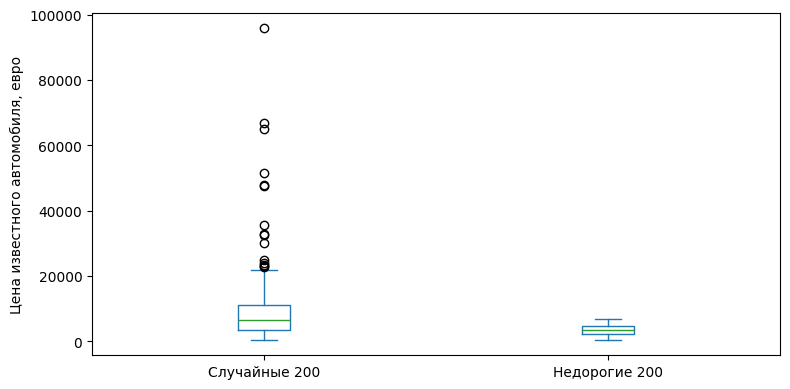

In [23]:
price_ranges = pd.DataFrame({"Случайные 200": random_context["Price"].reset_index(drop=True),
                             "Недорогие 200": cheap_context["Price"].reset_index(drop=True)})
price_ranges.plot.box(figsize=(8, 4))
plt.ylabel("Цена известного автомобиля, евро")
plt.tight_layout()
plt.show()

### TabPFN с каждым контекстом

Возвращаемся к четырём числовым признакам. В двух запусках меняется состав известных строк, а число строк и validation сохраняются.

In [24]:
pfn.fit(random_context[numeric_features], random_context["Price"])
pfn_random = pfn.predict(valid[numeric_features])
evaluate("TabPFN / случайные 200", valid["Price"], pfn_random).round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabPFN / случайные 200,2488.0,4425.0


In [25]:
pfn.fit(cheap_context[numeric_features], cheap_context["Price"])
pfn_cheap = pfn.predict(valid[numeric_features])
evaluate("TabPFN / недорогие 200", valid["Price"], pfn_cheap).round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabPFN / недорогие 200,4743.0,7954.0


### TabICLv2 с каждым контекстом

In [26]:
icl.fit(random_context[numeric_features], random_context["Price"])
icl_random = icl.predict(valid[numeric_features])
evaluate("TabICL / случайные 200", valid["Price"], icl_random).round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabICL / случайные 200,2574.0,4536.0


In [27]:
icl.fit(cheap_context[numeric_features], cheap_context["Price"])
icl_cheap = icl.predict(valid[numeric_features])
evaluate("TabICL / недорогие 200", valid["Price"], icl_cheap).round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabICL / недорогие 200,4826.0,8047.0


### Размечаем проверочные машины по ценовым группам

Граница совпадает с границей отбора недорогого контекста. Эта группа нужна только для анализа ошибок. Модель не получает ни правильную цену, ни группу проверочной машины.

In [28]:
group_names = np.where(valid["Price"] <= price_limit, "Недорогие", "Дорогие")
valid_groups = pd.Series(group_names, index=valid.index, name="Группа")
valid_groups.value_counts()

Группа
Недорогие    161
Дорогие      139
Name: count, dtype: int64

### Собираем прогнозы по столбцам

Каждая строка соответствует тому же автомобилю из valid. index=valid.index сохраняет правильное соответствие строк.

In [29]:
context_predictions = pd.DataFrame({"TabPFN / случайные": pfn_random,
                                    "TabPFN / недорогие": pfn_cheap,
                                    "TabICL / случайные": icl_random,
                                    "TabICL / недорогие": icl_cheap}, index=valid.index)
context_predictions.head()

,TabPFN / случайные,TabPFN / недорогие,TabICL / случайные,TabICL / недорогие
11497,5513.647567,4305.178992,4815.617676,4309.517090
28181,25670.464763,5424.171090,25113.136719,5348.954102
23719,3580.555729,3426.489764,3667.397949,3133.164307
3329,27144.940744,5267.611445,24287.886719,5217.224609
3878,5779.240953,5129.322289,5928.348633,5088.842285


### Считаем MAE через pandas

sub(..., axis=0) вычитает правильную цену из каждого прогноза в строке. abs() берёт модуль ошибки. groupby(...).mean() усредняет ошибки отдельно для двух групп.

In [30]:
errors = context_predictions.sub(valid["Price"], axis=0)
absolute_errors = errors.abs()
group_mae = absolute_errors.groupby(valid_groups).mean()
group_mae.round(0)

,TabPFN / случайные,TabPFN / недорогие,TabICL / случайные,TabICL / недорогие
Группа,,,,
Дорогие,3505.0,9084.0,3696.0,9244.0
Недорогие,1609.0,995.0,1606.0,1011.0


### Считаем RMSE по тем же группам

Возводим ошибки в квадрат, усредняем в группе и извлекаем квадратный корень.

In [31]:
squared_errors = errors.pow(2)
mean_squared_errors = squared_errors.groupby(valid_groups).mean()
group_rmse = np.sqrt(mean_squared_errors)
group_rmse.round(0)

,TabPFN / случайные,TabPFN / недорогие,TabICL / случайные,TabICL / недорогие
Группа,,,,
Дорогие,6052.0,11607.0,6199.0,11741.0
Недорогие,2206.0,1257.0,2274.0,1274.0


#### Задание студенту

Для каждой модели сопоставьте ошибки на дорогих и недорогих машинах при смене контекста. Объясните, почему один и тот же отбор известных примеров помогает одной группе и мешает другой.

### 5.2. Подбираем контекст с помощью KNN

Теперь сравним три способа отбора **из одних и тех же 1 000 строк context**: случайные 200, 200 ближайших по числовым признакам и 200 с приоритетом своей марки.

Для быстрого опыта берём первые **50 машин из valid**. Все шесть запусков проверяем на этих же 50 машинах. Их цены используются только для расчёта метрик. Этот опыт имеет отдельную таблицу; основные сравнения на 300 машинах продолжаются в следующем разделе.

В каждом контексте ровно 200 известных цен. Трансформеры получают четыре числовых признака и обычную цену; марка используется только при отборе контекста.

In [32]:
selection_valid = valid.iloc[:50].copy()
fixed_context = context.iloc[:200].copy()
print("Проверочных машин:", len(selection_valid))
print("Строк в случайном контексте:", len(fixed_context))

Проверочных машин: 50
Строк в случайном контексте: 200


#### Масштабируем признаки для поиска соседей

Пробег и объём двигателя имеют разные единицы. `StandardScaler` приводит их к сопоставимому масштабу. Он настраивается только по известным машинам. Трансформеру далее передаём исходные значения.

In [33]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

neighbor_scaler = StandardScaler()
context_scaled = neighbor_scaler.fit_transform(context[numeric_features])
query_scaled = neighbor_scaler.transform(selection_valid[numeric_features])

#### Находим позиции 200 соседей для каждой машины

`kneighbors(..., return_distance=False)` возвращает позиции строк в `context`, а не их исходные индексы. Поэтому строки соседей получаем через `iloc`.

KNN здесь выбирает примеры. Цену по ним предсказывает трансформер.

In [34]:
neighbor_search = NearestNeighbors(n_neighbors=200)
neighbor_search.fit(context_scaled)
neighbor_positions = neighbor_search.kneighbors(query_scaled, return_distance=False)
print("Машин × соседей:", neighbor_positions.shape)
first_neighbors = context.iloc[neighbor_positions[0]]
first_neighbors[numeric_features + ["Make", "Price"]].head()

Машин × соседей: (50, 200)


,Year,Distance,Engine,km_year,Make,Price
23439,2004,220000.0,2200.0,12222.222222,Mercedes,2700.0
4409,2006,230000.0,2200.0,14375.000000,Hyundai,8599.0
25850,2005,226000.0,2500.0,13294.117647,Volkswagen,5900.0
13523,2004,213000.0,2500.0,11833.333333,KIA,6500.0
25750,2006,243222.0,2200.0,15201.375000,Toyota,3400.0


#### Один цикл — отдельный контекст для каждого запроса

Для каждой проверочной машины берём её соседей, вызываем `fit()` для замены контекста и получаем один прогноз. Повторного обучения весов здесь нет. Цикл нужен, потому что у каждой машины свой набор известных примеров.

In [35]:
def predict_with_neighbors(model):
    predictions = []
    for position, neighbors in enumerate(neighbor_positions):
        known = context.iloc[neighbors]
        model.fit(known[numeric_features], known["Price"])
        query = selection_valid.iloc[[position]]
        prediction = model.predict(query[numeric_features])[0]
        predictions.append(prediction)
    return np.asarray(predictions)

### 5.3. Подбираем контекст по марке

#### Сначала своя марка, затем остальные

В 1 000 известных строках может быть мало машин нужной марки. Поэтому ставим их первыми, затем добавляем остальные и берём первые 200 строк. Это **контекст с приоритетом марки**, а не обязательно 200 автомобилей одной марки.

`eq()` создаёт условие равенства, `ne()` — неравенства. `loc` отбирает строки, `concat` ставит две таблицы друг под другом, `iloc[:200]` ограничивает размер.

In [36]:
def context_for_make(make):
    same_make = context.loc[context["Make"].eq(make)]
    other_makes = context.loc[context["Make"].ne(make)]
    ordered_context = pd.concat([same_make, other_makes])
    return ordered_context.iloc[:200]

#### Проверяем отбор на одном автомобиле

`iloc[0]` берёт первую проверочную машину. `value_counts()` показывает, сколько автомобилей каждой марки попало в её контекст.

In [37]:
first_make = selection_valid.iloc[0]["Make"]
make_context_example = context_for_make(first_make)
same_make_count = make_context_example["Make"].eq(first_make).sum()
print("Марка запроса:", first_make)
print("Размер контекста:", len(make_context_example))
print("Из них той же марки:", same_make_count)
make_context_example["Make"].value_counts().head()

Марка запроса: Ford
Размер контекста: 200
Из них той же марки: 46


Make
Ford          46
Volkswagen    21
Toyota        20
Renault       17
Mercedes      14
Name: count, dtype: int64

#### Один контекст для всех проверочных машин одной марки

`groupby("Make", observed=True)` перебирает марки, которые встречаются среди 50 запросов. Внутри группы выбираем контекст и сразу прогнозируем цены всех машин этой марки. Прогнозы записываем по исходным индексам, чтобы сохранить порядок строк.

In [38]:
def predict_with_make(model):
    predictions = pd.Series(index=selection_valid.index, dtype=float)
    for make, queries in selection_valid.groupby("Make", observed=True):
        known = context_for_make(make)
        model.fit(known[numeric_features], known["Price"])
        predictions.loc[queries.index] = model.predict(queries[numeric_features])
    return predictions.to_numpy()

### 5.4. Сравниваем три контекста на одинаковых запросах

Два запуска с персональным отбором требуют нескольких вызовов `fit()` и `predict()`, поэтому выполняются дольше одного общего контекста. В сохранённом запуске весь этот опыт для двух моделей занял около полутора минут на CPU.

#### TabPFN: случайный контекст

In [39]:
selection_pfn = clone(pfn)
selection_pfn.fit(fixed_context[numeric_features], fixed_context["Price"])
selection_pfn_random = selection_pfn.predict(selection_valid[numeric_features])
pfn_random_score = evaluate("TabPFN / случайные 200", selection_valid["Price"], selection_pfn_random)

#### TabPFN: KNN-контекст

In [40]:
selection_pfn_knn = predict_with_neighbors(selection_pfn)
pfn_knn_score = evaluate("TabPFN / KNN 200", selection_valid["Price"], selection_pfn_knn)

#### TabPFN: контекст с приоритетом марки

In [41]:
selection_pfn_make = predict_with_make(selection_pfn)
pfn_make_score = evaluate("TabPFN / марка + дополнение", selection_valid["Price"], selection_pfn_make)

#### TabICLv2: случайный контекст

In [42]:
selection_icl = clone(icl)
selection_icl.fit(fixed_context[numeric_features], fixed_context["Price"])
selection_icl_random = selection_icl.predict(selection_valid[numeric_features])
icl_random_score = evaluate("TabICL / случайные 200", selection_valid["Price"], selection_icl_random)

#### TabICLv2: KNN-контекст

In [43]:
selection_icl_knn = predict_with_neighbors(selection_icl)
icl_knn_score = evaluate("TabICL / KNN 200", selection_valid["Price"], selection_icl_knn)

#### TabICLv2: контекст с приоритетом марки

In [44]:
selection_icl_make = predict_with_make(selection_icl)
icl_make_score = evaluate("TabICL / марка + дополнение", selection_valid["Price"], selection_icl_make)

#### Общая таблица: MAE и RMSE на 50 машинах

In [45]:
selection_results = pd.concat([
    pfn_random_score, pfn_knn_score, pfn_make_score,
    icl_random_score, icl_knn_score, icl_make_score,
], ignore_index=True)
selection_results["Проверочных машин"] = len(selection_valid)
selection_results["Строк контекста"] = len(fixed_context)
selection_results.round(0)

,Вариант,"MAE, евро","RMSE, евро",Проверочных машин,Строк контекста
0,TabPFN / случайные 200,2767.0,4686.0,50,200
1,TabPFN / KNN 200,2449.0,4995.0,50,200
2,TabPFN / марка + дополнение,2213.0,3504.0,50,200
3,TabICL / случайные 200,2939.0,4966.0,50,200
4,TabICL / KNN 200,2521.0,5324.0,50,200
5,TabICL / марка + дополнение,2356.0,3612.0,50,200


#### Разбор результата

В сохранённом запуске приоритет марки снизил обе ошибки у обеих моделей. KNN снизил MAE, но увеличил RMSE: средняя абсолютная ошибка уменьшилась, а крупные промахи стали сильнее влиять на результат. Близость по выбранным четырём числам не гарантирует близкую цену.

#### Задание студенту

1. По таблице выберите контекст отдельно для MAE и RMSE. Подтвердите выбор числами.
2. Объясните, почему добавление остальных марок позволяет сохранить одинаковый размер контекста.
3. Для проверки устойчивости повторите опыт на следующих 50 машинах: `valid.iloc[50:100]`. Нужно заново получить `query_scaled` и `neighbor_positions`, затем повторить прогнозы и расчёт метрик. Сравните выводы. Тестовую выборку в этом опыте не используйте.

## 6. Эксперимент 4. Линейная регрессия и логарифм цены

### Готовим восемь признаков для LR

Далее в каждом сравнении используются те же 1 000 известных автомобилей и восемь признаков. StandardScaler преобразует числовые колонки, OneHotEncoder — четыре категориальные. Преобразования настраиваются во время fit() по известным строкам.

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge

preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_features),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_features),
])

### LR с обычной ценой

In [47]:
lr_price = make_pipeline(clone(preprocessor), LinearRegression())
lr_price.fit(context[expanded_features], context["Price"])
lr_price_valid = lr_price.predict(valid[expanded_features])
lr_price_score = evaluate("LR / Price", valid["Price"], lr_price_valid)
lr_price_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,LR / Price,3534.0,5139.0


### Преобразуем целевую переменную

log1p(Price) — натуральный логарифм числа 1 + Price. Этот ряд станет целью модели. В исходной таблице Price остаётся в евро.

In [48]:
y_log = np.log1p(context["Price"])
y_log.head()

28259    9.305741
12254    8.832150
24067    6.552508
3435     8.343078
23929    8.101981
Name: Price, dtype: float64

### LR с логарифмом цены

Модель предсказывает логарифм. expm1() возвращает прогноз в евро до расчёта MAE и RMSE.

In [49]:
lr_log = make_pipeline(clone(preprocessor), LinearRegression())
lr_log.fit(context[expanded_features], y_log)
lr_log_valid = np.expm1(lr_log.predict(valid[expanded_features]))
lr_log_score = evaluate("LR / log", valid["Price"], lr_log_valid)
lr_log_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,LR / log,2081.0,3566.0


### TabPFN с логарифмом цены

pfn_price из раздела 4 уже хранит вариант с обычной ценой и восемью признаками. Создаём отдельно pfn_log.

In [50]:
pfn_log = clone(pfn_price)
pfn_log.fit(context[expanded_features], y_log)
pfn_log_valid = np.expm1(pfn_log.predict(valid[expanded_features]))
pfn_log_score = evaluate("TabPFN / log", valid["Price"], pfn_log_valid)
pfn_log_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabPFN / log,1951.0,3543.0


### TabICLv2 с логарифмом цены

In [51]:
icl_log = clone(icl_price)
icl_log.fit(context[expanded_features], y_log)
icl_log_valid = np.expm1(icl_log.predict(valid[expanded_features]))
icl_log_score = evaluate("TabICL / log", valid["Price"], icl_log_valid)
icl_log_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabICL / log,1739.0,3262.0


### Сводная таблица шести запусков

concat() ставит шесть однострочных результатов друг под другом. Каждый результат получен на одних и тех же 300 автомобилях validation.

In [52]:
validation_results = pd.concat([lr_price_score, lr_log_score,
                                pfn_price_score, pfn_log_score,
                                icl_price_score, icl_log_score], ignore_index=True)
validation_results.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,LR / Price,3534.0,5139.0
1,LR / log,2081.0,3566.0
2,TabPFN / Price,2075.0,3892.0
3,TabPFN / log,1951.0,3543.0
4,TabICL / Price,1997.0,3821.0
5,TabICL / log,1739.0,3262.0


### Разбор сохранённого результата

После логарифма MAE LR снизилась примерно с 3 534 до 2 081 евро. Это почти MAE TabPFN с обычной ценой — 2 075 евро. Сравнение архитектур изменилось после преобразования цели простой модели.

TabICLv2 с логарифмом получил наименьшую MAE и RMSE на validation. Проверим перенос этого результата на test.

#### Задание студенту

По таблице запишите отдельно эффект логарифма для каждой модели и разницу между LR и TAB при одинаковой цели. Затем выберите модель по MAE и по RMSE и обоснуйте оба решения.

## 7. Итоговая проверка на test

### Сначала упорядочиваем результаты validation

sort_values() сортирует строки по MAE. Смотрим название выбранного варианта в первой строке. Выбор делаем до расчёта ошибок на test.

In [53]:
ordered_results = validation_results.sort_values("MAE, евро")
ordered_results.round(0)

,Вариант,"MAE, евро","RMSE, евро"
5,TabICL / log,1739.0,3262.0
3,TabPFN / log,1951.0,3543.0
4,TabICL / Price,1997.0,3821.0
2,TabPFN / Price,2075.0,3892.0
1,LR / log,2081.0,3566.0
0,LR / Price,3534.0,5139.0


### Считаем контрольный результат LR

Выбираем LR с логарифмом по таблице validation. Она уже обучена, поэтому вызываем только predict().

In [54]:
lr_test_prediction = np.expm1(lr_log.predict(test[expanded_features]))
lr_test_score = evaluate("LR / log", test["Price"], lr_test_prediction)
lr_test_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,LR / log,2492.0,5055.0


### Проверяем выбранный трансформер

В сохранённом запуске выбран TabICLv2 с логарифмом. Сохраняем этот выбор явно в final_model. Если после изменения условий другой вариант стал лучше на validation, замените объект модели и соответствующее обратное преобразование.

In [55]:
final_model = icl_log
test_prediction = np.expm1(final_model.predict(test[expanded_features]))
tab_test_score = evaluate("TabICL / log", test["Price"], test_prediction)
tab_test_score.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,TabICL / log,2015.0,3602.0


### Сопоставляем две итоговые строки

In [56]:
test_results = pd.concat([lr_test_score, tab_test_score], ignore_index=True)
test_results["Автомобилей"] = len(test)
test_results.round(0)

,Вариант,"MAE, евро","RMSE, евро",Автомобилей
0,LR / log,2492.0,5055.0,500
1,TabICL / log,2015.0,3602.0,500


### Фактическая цена и прогноз

Каждая точка — один из 500 автомобилей test. Диагональ соответствует точному прогнозу.

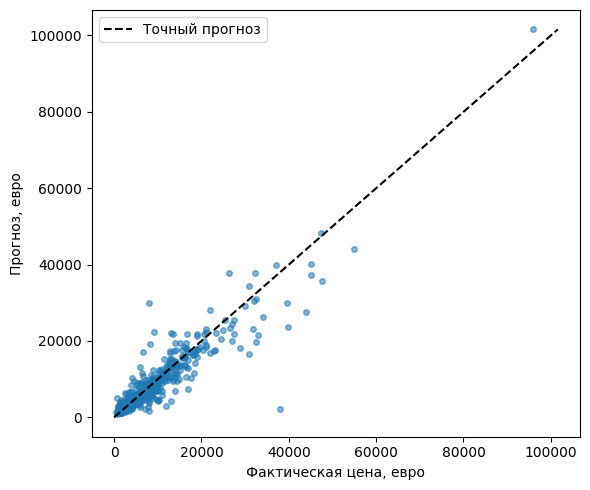

In [57]:
plt.figure(figsize=(6, 5))
plt.scatter(test["Price"], test_prediction, s=16, alpha=0.55)
limit = max(test["Price"].max(), test_prediction.max())
plt.plot([0, limit], [0, limit], "k--", label="Точный прогноз")
plt.xlabel("Фактическая цена, евро")
plt.ylabel("Прогноз, евро")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Короткий бонус. Генерируем новые столбцы с помощью TabPFN

### Что именно добавляем в таблицу

Для каждого автомобиля TabPFN вычислит **192 новых числовых признака**. Мы дадим им названия `TAB_0`, `TAB_1`, …, `TAB_191` и добавим справа к восьми исходным столбцам. Из 500 строк × 8 признаков получится 500 строк × 200 признаков.

Это аугментация **признаков**: автомобилей столько же, столбцов больше. Новые значения — внутреннее представление строки из трансформера (`embeddings`). Это не новые марки или искусственно придуманные цены; отдельный столбец TAB обычно не имеет простого бытового названия.

### Какие цены получает каждая модель

Известные 1 000 машин делим пополам. TabPFN получает 500 машин `support` с ценами как контекст. Для других 500 машин `lr_part` он генерирует столбцы, не получая их цен. Ridge обучается на этих 500 строках с новыми столбцами и их правильными ценами.

In [58]:
support, lr_part = train_test_split(context, test_size=0.5, random_state=42)
extractor = clone(pfn_log)
# Цены только опорных машин; веса TabPFN фиксированы.
extractor.fit(support[expanded_features], np.log1p(support["Price"]))
E_train = extractor.get_embeddings(lr_part[expanded_features], data_source="test")[0]
E_valid = extractor.get_embeddings(valid[expanded_features], data_source="test")[0]
print("Строк × новых признаков:", E_train.shape)

Строк × новых признаков: (500, 192)


### Смотрим сгенерированные столбцы TAB_0, TAB_1, …

Каждая строка `E_train` относится к тому же автомобилю из `lr_part`. Каждый столбец — к одной координате его внутреннего представления. Создаём DataFrame с исходными индексами машин, а `add_prefix("TAB_")` задаёт названия.

Выведем первые четыре новых столбца для пяти автомобилей. Всего новых столбцов 192.

In [59]:
Z_train = pd.DataFrame(E_train, index=lr_part.index).add_prefix("TAB_")
Z_valid = pd.DataFrame(E_valid, index=valid.index).add_prefix("TAB_")
Z_train.iloc[:5, :4]

,TAB_0,TAB_1,TAB_2,TAB_3
12019,0.020983,-0.025665,0.038149,0.193419
15905,0.011562,0.079016,0.088437,-0.016625
15434,-0.026828,0.105076,0.149451,0.029048
4830,0.020533,0.020043,-0.050375,0.154343
27591,-0.048588,0.082844,0.101631,0.047143


### Приклеиваем новые столбцы к исходным

`join()` сопоставляет строки по индексу автомобиля. Покажем изменение размера и фрагмент итоговой таблицы: исходные сведения слева, сгенерированные числа справа. Правильную цену в признаки не добавляем.

In [60]:
X_augmented = lr_part[expanded_features].join(Z_train)
X_augmented_valid = valid[expanded_features].join(Z_valid)
print("До добавления:", lr_part[expanded_features].shape)
print("После добавления:", X_augmented.shape)
preview_columns = ["Make", "Year", "Distance", "TAB_0", "TAB_1", "TAB_2"]
X_augmented[preview_columns].head()

До добавления: (500, 8)
После добавления: (500, 200)


,Make,Year,Distance,TAB_0,TAB_1,TAB_2
12019,Rare,2018,31600.0,0.020983,-0.025665,0.038149
15905,Rare,2009,206000.0,0.011562,0.079016,0.088437
15434,Toyota,2006,280000.0,-0.026828,0.105076,0.149451
4830,BMW,2014,73000.0,0.020533,0.020043,-0.050375
27591,Toyota,2007,165000.0,-0.048588,0.082844,0.101631


### Контрольная Ridge на всех 1 000 известных машинах

Сравниваем с моделью, которой доступны те же 1 000 цен. В гибриде 500 цен использует TabPFN и 500 — Ridge.

In [61]:
ridge_plain = make_pipeline(clone(preprocessor), Ridge(alpha=10))
ridge_plain.fit(context[expanded_features], y_log)
ridge_plain_prediction = np.expm1(ridge_plain.predict(valid[expanded_features]))
ridge_plain_score = evaluate("Ridge / log / исходные признаки", valid["Price"], ridge_plain_prediction)

### Обучаем Ridge на исходных и сгенерированных столбцах

В список числовых признаков включаем четыре исходных числовых столбца и 192 названия из `Z_train`. Четыре категориальных столбца по-прежнему кодируем через OneHotEncoder. Ridge с alpha=10 получает все эти признаки и логарифм цены.

Для новых автомобилей гибриду тоже потребуется TabPFN: сначала получить столбцы TAB, затем передать расширенную строку Ridge.

In [62]:
augmented_numbers = numeric_features + Z_train.columns.to_list()
augmented_preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), augmented_numbers),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_features),
])
ridge_augmented = make_pipeline(augmented_preprocessor, Ridge(alpha=10))
ridge_augmented.fit(X_augmented, np.log1p(lr_part["Price"]))
augmented_prediction = np.expm1(ridge_augmented.predict(X_augmented_valid))
ridge_augmented_score = evaluate("Ridge / log / плюс TAB", valid["Price"], augmented_prediction)

In [63]:
augmentation_results = pd.concat([ridge_plain_score, ridge_augmented_score], ignore_index=True)
augmentation_results.round(0)

,Вариант,"MAE, евро","RMSE, евро"
0,Ridge / log / исходные признаки,2072.0,3287.0
1,Ridge / log / плюс TAB,1942.0,3543.0


### Разбор бонуса

В сохранённом запуске новые признаки уменьшили MAE Ridge, но увеличили RMSE на validation. Бонус показывает, как проверить пользу дополнительных признаков по нужной метрике. Он оценивается отдельно от основного выбора регрессора.

[Публичный пример извлечения признаков TabPFN](https://github.com/PriorLabs/tabpfn-extensions/blob/main/examples/embedding/get_embeddings.py).

## Итоговое задание студенту

На основе полученных таблиц обоснуйте выбор модели для двух целей — уменьшить средний абсолютный промах и уменьшить крупные промахи. Укажите роль логарифма цены, категориальных признаков и предобученного трансформера в полученном результате.

Все сравнения относятся к одному фиксированному разбиению. Повтор выбора context позволяет проверить устойчивость выводов к составу известных примеров.